# 02 - Gas, carbon and clean spark spread

Goal: does the electricity price follow the marginal cost of a gas plant?

## 1. Load and align series
- Electricity (hourly) -> daily average
- TTF gas (EUR/MWh) and EUA carbon (EUR/t): document source and gaps

**Sources**
- Gas: Yahoo Finance `TTF=F` (front-month TTF future, continuous series).
- Carbon: Investing.com "Carbon Emissions Futures" (nearest-December EUA future, continuous series, manual CSV download). The provider rolls to the next December contract before expiry (volume drops around 10 Dec 2024), which can create small artificial jumps.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

RAW = Path("..") / "data" / "raw"
PROCESSED = Path("..") / "data" / "processed"
FIGURES = Path("..") / "figures"
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

YEAR = "2024"
START, END = "2023-12-01", "2025-01-05"      # margin before/after the year (END is exclusive for Yahoo)
TTF_TICKER = "TTF=F"
EUA_FILE = RAW / "Carbon Emissions Futures Historical Data.csv"
TTF_CACHE = RAW / "ttf_daily.csv"            # local copy: no dependence on Yahoo at each run


def to_daily_close(hist, name):
    """Takes Ticker.history() output, returns daily close prices, one per date."""
    if hist.empty:
        raise ValueError(f"No data returned for {name}: check the ticker")
    s = hist["Close"].copy()
    s.index = s.index.tz_localize(None).normalize()
    s.name = name
    return s


def load_ttf():
    if TTF_CACHE.exists():
        return pd.read_csv(TTF_CACHE, index_col=0, parse_dates=True)["ttf"]
    s = to_daily_close(yf.Ticker(TTF_TICKER).history(start=START, end=END, auto_adjust=False), "ttf")
    s.to_csv(TTF_CACHE)
    return s


def load_eua(path):
    df = pd.read_csv(path)
    df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")     # US format: month first
    return df.set_index("Date").sort_index()["Price"].rename("eua")


ttf = load_ttf()
eua = load_eua(EUA_FILE)

ttf
rows: 273 | first: 2023-12-01 | last: 2025-01-03
NaN: 0 | duplicated dates: 0
gaps > 4 days: {datetime.date(2024, 4, 2): 5.0}
count    273.00
mean      34.85
std        6.39
min       22.93
25%       29.73
50%       34.21
75%       39.60
max       50.27


eua
rows: 278 | first: 2023-12-01 | last: 2025-01-03
NaN: 0 | duplicated dates: 0
gaps > 4 days: {datetime.date(2023, 12, 27): 5.0, datetime.date(2024, 4, 2): 5.0}
count    278.00
mean      66.86
std        5.10
min       52.51
25%       63.60
50%       67.57
75%       70.32
max       77.98




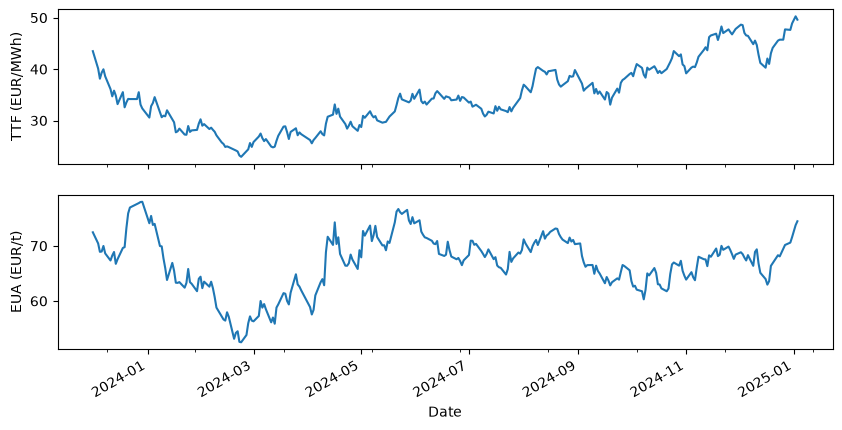

In [2]:
def audit(s):
    gaps = s.index.to_series().diff().dt.days
    print(s.name)
    print("rows:", len(s), "| first:", s.index.min().date(), "| last:", s.index.max().date())
    print("NaN:", int(s.isna().sum()), "| duplicated dates:", int(s.index.duplicated().sum()))
    print("gaps > 4 days:", {k.date(): v for k, v in gaps[gaps > 4].items()})
    print(s.describe().round(2).to_string())
    print('\n')


audit(ttf)
audit(eua)

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ttf.plot(ax=ax[0]); ax[0].set_ylabel("TTF (EUR/MWh)")
eua.plot(ax=ax[1]); ax[1].set_ylabel("EUA (EUR/t)")
plt.show()

### Alignment rule (D-1)
The day-ahead order book (SDAC) closes at **12:00 CET/CEST on D-1** (source: SDAC Fallback Manual, EPEX Spot), and the results are published from 12:55. Gas and carbon prices of day D are therefore taken from D-1 (or the last trading day before it).

Approximation: the daily close of D-1 is set *after* the auction closes, so it is slightly ahead of what traders knew at 12:00. The strictly known information is the close of D-2; a robustness check with D-2 is run in section 3.

Two steps, in this order: forward-fill on a calendar of all days (weekends, holidays), then shift by one day.

In [3]:
hourly = pd.read_parquet(PROCESSED / "ES_hourly_2024.parquet")

# Daily electricity: mean of hourly MW / prices over local days
daily = hourly[["price", "solar", "load"]].resample("D").mean()
daily.index = daily.index.tz_localize(None)            # plain dates, no timezone

data = pd.DataFrame(index=pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31", freq="D"))
data["power"] = daily["price"]
data["solar_share"] = daily["solar"] / daily["load"]   # share of demand covered by solar

# Fuels: ffill on all calendar days (limit = longest acceptable gap), then D-1
cal = pd.date_range(START, END, freq="D")
fuels = (
    pd.DataFrame({"ttf": ttf.reindex(cal), "eua": eua.reindex(cal)})
    .ffill(limit=5)
    .shift(1)
)
data = data.join(fuels)

assert data.shape[0] == 366, data.shape
assert not data.isna().any().any(), data.isna().sum()
data.head()

,power,solar_share,ttf,eua
2024-01-01,36.242500,0.124184,32.349998,77.98
2024-01-02,40.907917,0.074554,32.349998,77.98
2024-01-03,55.084167,0.051142,30.572001,74.09
2024-01-04,91.357917,0.035423,32.794998,75.42
2024-01-05,68.615417,0.093274,33.410000,73.78


In [4]:
# Check around Easter: fuels must stay constant while the market is closed
data.loc["2024-03-28":"2024-04-03"]

,power,solar_share,ttf,eua
2024-03-28,0.660000,0.127034,27.687000,62.61
2024-03-29,4.052500,0.133790,27.340000,61.93
2024-03-30,4.515833,0.134762,27.340000,61.93
2024-03-31,0.832609,0.111130,27.340000,61.93
2024-04-01,2.763750,0.203150,27.340000,61.93
2024-04-02,9.851250,0.156557,27.340000,61.93
2024-04-03,9.030833,0.207743,26.202999,58.90


## 2. Marginal cost of a gas plant

A combined-cycle plant burns more than 1 MWh of gas per MWh of electricity (efficiency eta < 1), and emits `EF` tonnes of CO2 per MWh of gas burnt:

cost (EUR/MWh_e) = gas_price / eta + EF * carbon_price / eta = (gas_price + EF * carbon_price) / eta

- `EF` = 0.202 tCO2/MWh of gas: IPCC 2006 Guidelines, vol. 2, ch. 2, table 2.2: 56.1 tCO2/TJ (net calorific basis) for natural gas, i.e. 56.1 x 0.0036.
- `ETA` = 0.50: **assumption**, no single official figure for the Spanish fleet was found. The EEA indicates that CCGT plants can reach about 60 %, and the EU average for conventional thermal plants was about 47-49 % (2007). A sensitivity analysis (0.45 to 0.60) is run in section 3.

In [5]:
ETA = 0.50
EF = 0.202        # tCO2 per MWh of gas (thermal)


def marginal_cost(ttf, eua, eta=ETA, ef=EF):
    """Fuel + carbon cost of 1 MWh of electricity from a gas plant (EUR/MWh_e)."""
    return (ttf + ef * eua) / eta


data["gas_cost"] = data["ttf"] / ETA
data["carbon_cost"] = EF * data["eua"] / ETA
data["mc"] = data["gas_cost"] + data["carbon_cost"]
data['carbon_share_mc_percent']=data["carbon_cost"]/data['mc']*100
assert np.allclose(data["mc"], marginal_cost(data["ttf"], data["eua"]))

# Check by hand on one day
d = "2024-04-03"
row = data.loc[d]
print(d, "| ttf", round(row.ttf, 2), "| eua", round(row.eua, 2))
print("gas cost    :", round(row.ttf / ETA, 1))
print("carbon cost :", round(EF * row.eua / ETA, 1))
print("marginal cost:", round(row.mc, 1))

print("\nMean carbon share of marginal cost:", round((data["carbon_share_mc_percent"]).mean(), 1), "%")
data[["gas_cost", "carbon_cost", "mc", "carbon_share_mc_percent"]].describe().round(1)

2024-04-03 | ttf 26.2 | eua 58.9
gas cost    : 52.4
carbon cost : 23.8
marginal cost: 76.2

Mean carbon share of marginal cost: 28.3 %


,gas_cost,carbon_cost,mc,carbon_share_mc_percent
count,366.0,366.0,366.0,366.0
mean,69.3,26.9,96.1,28.3
std,12.9,2.0,13.9,3.2
min,45.9,21.2,67.1,22.2
25%,58.7,25.6,85.5,25.5
50%,68.2,27.2,96.2,29.3
75%,79.3,28.3,105.9,31.1
max,97.3,31.5,125.1,32.9


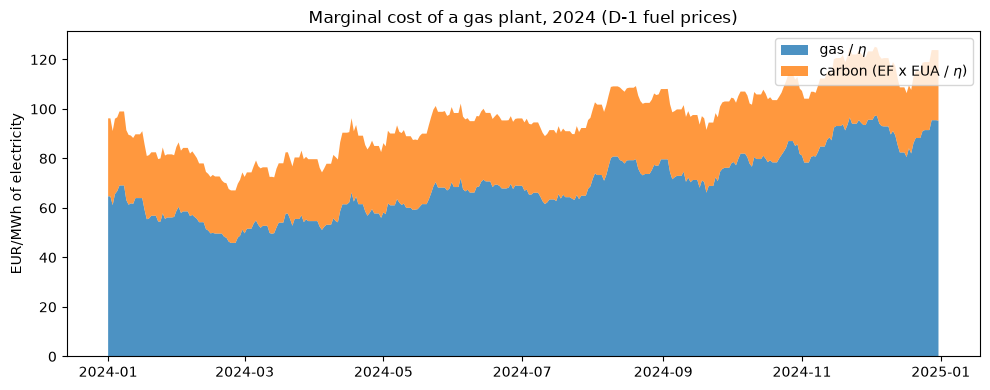

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(data.index, data["gas_cost"], data["carbon_cost"], labels=[r"gas / $\eta$", r"carbon (EF x EUA / $\eta$)"], alpha=0.8)
ax.set_ylabel("EUR/MWh of electricity")
ax.set_title("Marginal cost of a gas plant, 2024 (D-1 fuel prices)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES / "02_marginal_cost.png", dpi=150)
plt.show()

## 3. Clean spark spread
spread = electricity_price - marginal_cost
- Plot over time; compare with solar share

Positive: a gas plant makes money at that price. Negative: it does not, so gas is not the price-setter.

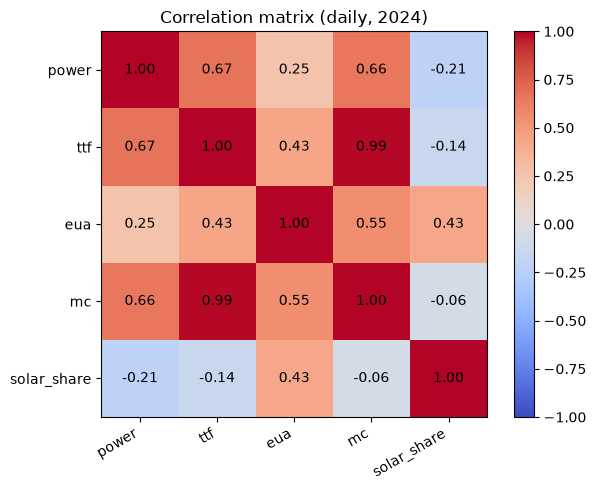

In [7]:
data["css"] = data["power"] - data["mc"]

cols = ["power", "ttf", "eua", "mc", "solar_share"]
corr = data[cols].corr()          # Pearson ; method="spearman" possible

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=30, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)
ax.set_title("Correlation matrix (daily, 2024)")
fig.tight_layout()
fig.savefig(FIGURES / "02_correlation_matrix.png", dpi=150)
plt.show()


In [8]:
monthly = data.resample("MS").agg(
    power=("power", "mean"), mc=("mc", "mean"), css=("css", "mean"),
    pct_days_positive=("css", lambda s: (s > 0).mean() * 100), solar_share=("solar_share", "mean"),
).round(1)
monthly.index = monthly.index.strftime("%Y-%m")
monthly

,power,mc,css,pct_days_positive,solar_share
2024-01,74.1,87.9,-13.8,19.4,0.1
2024-02,40.0,75.6,-35.6,0.0,0.1
2024-03,20.3,77.6,-57.4,0.0,0.2
2024-04,13.7,84.6,-70.9,0.0,0.2
2024-05,30.4,92.6,-62.2,0.0,0.3
2024-06,56.1,97.0,-40.9,3.3,0.3
2024-07,72.3,92.4,-20.1,29.0,0.3
2024-08,91.1,105.3,-14.2,32.3,0.3
2024-09,72.6,99.3,-26.7,16.7,0.2
2024-10,68.5,106.8,-38.3,0.0,0.2


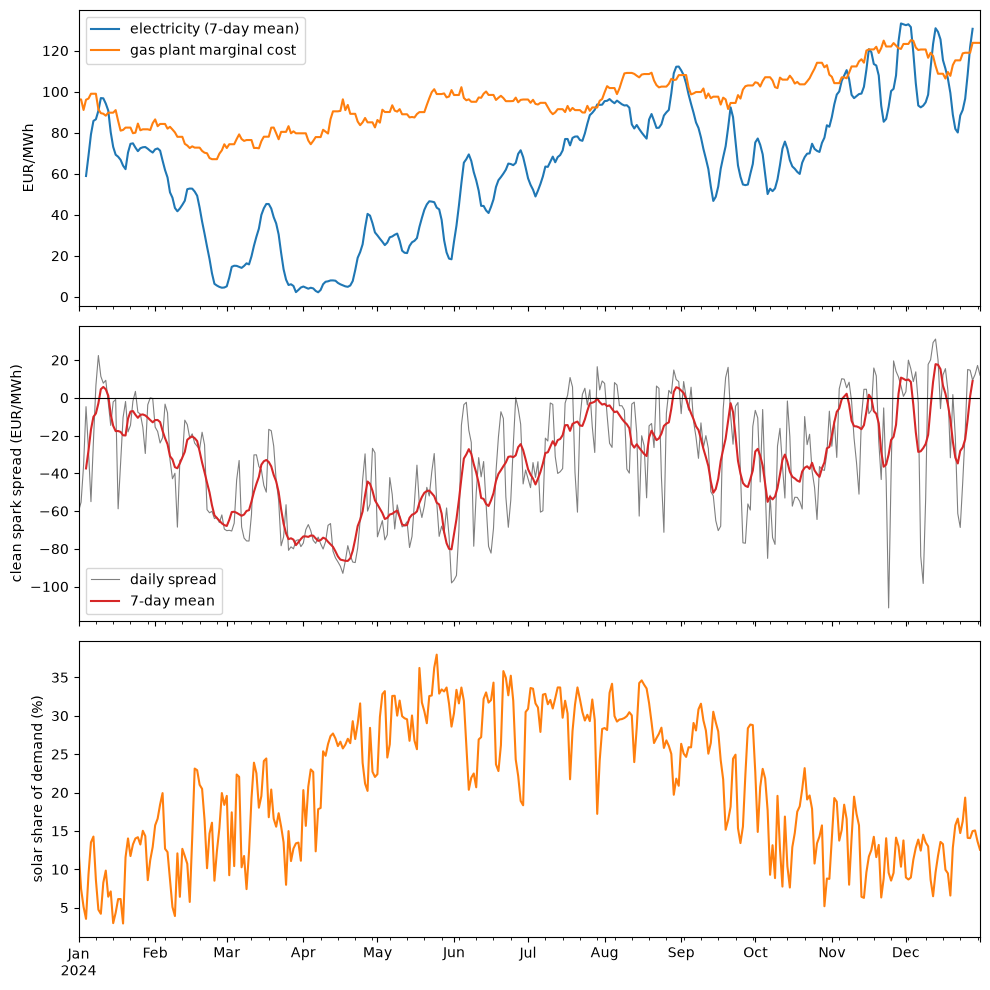

In [9]:
fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

data["power"].rolling(7, center=True).mean().plot(ax=ax[0], label="electricity (7-day mean)")
data["mc"].plot(ax=ax[0], label="gas plant marginal cost")
ax[0].set_ylabel("EUR/MWh"); ax[0].legend()

data["css"].plot(ax=ax[1], color="grey", lw=0.8, label="daily spread")
data["css"].rolling(7, center=True).mean().plot(ax=ax[1], color="C3", label="7-day mean")
ax[1].axhline(0, color="black", lw=0.8); ax[1].set_ylabel("clean spark spread (EUR/MWh)"); ax[1].legend()

(data["solar_share"] * 100).plot(ax=ax[2], color="C1")
ax[2].set_ylabel("solar share of demand (%)")

fig.tight_layout()
fig.savefig(FIGURES / "02_spread_over_time.png", dpi=150)
plt.show()

slope -0.83 EUR/MWh per solar point | R2 0.05 | Spearman -0.23


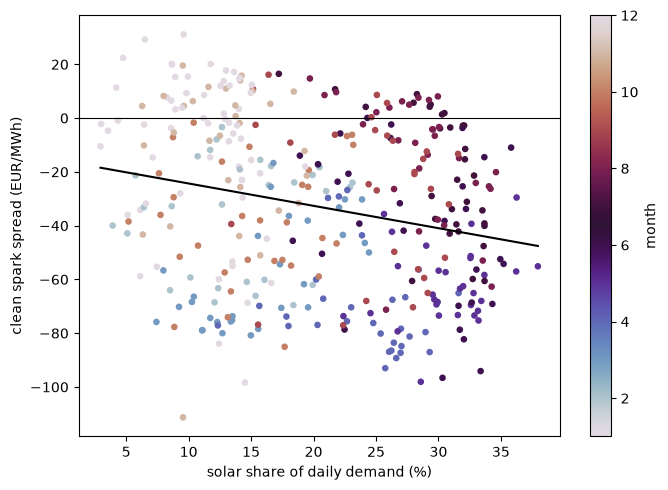

In [10]:
# Relation between the spread and the solar share (daily)
from scipy import stats

x, y = data["solar_share"] * 100, data["css"]
fit = stats.linregress(x, y)
print(f"slope {fit.slope:.2f} EUR/MWh per solar point | R2 {fit.rvalue**2:.2f} | Spearman {x.corr(y, method='spearman'):.2f}")

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(x, y, c=data.index.month, cmap="twilight", s=14)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("solar share of daily demand (%)"); ax.set_ylabel("clean spark spread (EUR/MWh)")
fig.colorbar(sc, label="month")
fig.tight_layout()
fig.savefig(FIGURES / "02_spread_vs_solar.png", dpi=150)
xs = np.array([x.min(), x.max()])
ax.plot(xs, fit.intercept + fit.slope * xs, color="black")
plt.show()

### Hour of day: when does the price follow the gas cost?
Daily averages mix hours with and without solar. Here each hourly price is compared to the marginal cost of its day.

Mean spread 12-15 h: -57.3 | share of hours > 0: 5 %
Mean spread 20-22 h: -5.2 | share of hours > 0: 53 %


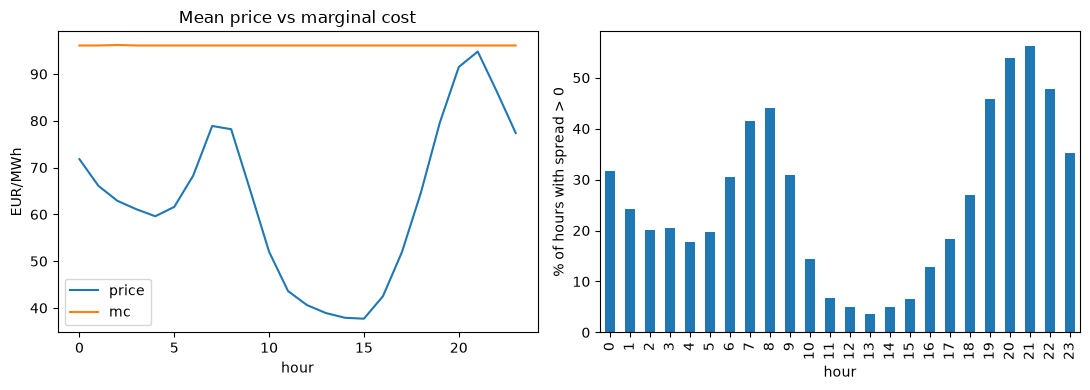

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
price,71.8,66.1,62.9,61.1,59.6,61.6,68.3,78.9,78.2,65.2,...,37.9,37.7,42.5,51.9,64.6,79.6,91.5,94.8,86.3,77.4
mc,96.1,96.1,96.2,96.1,96.1,96.1,96.1,96.1,96.1,96.1,...,96.1,96.1,96.1,96.1,96.1,96.1,96.1,96.1,96.1,96.1
css,-24.4,-30.0,-33.3,-35.1,-36.5,-34.5,-27.8,-17.2,-17.9,-30.9,...,-58.3,-58.4,-53.7,-44.2,-31.6,-16.5,-4.6,-1.3,-9.8,-18.7
pct_positive,31.7,24.3,20.2,20.5,17.8,19.7,30.6,41.5,44.0,30.9,...,4.9,6.6,12.8,18.3,27.0,45.9,53.8,56.3,47.8,35.2


In [11]:
h = hourly[["price"]].copy()
dates = h.index.tz_localize(None).normalize()
h["mc"] = data["mc"].loc[dates].to_numpy()
h["css"] = h["price"] - h["mc"]
h["hour"] = h.index.hour
h = h[h.index.year == int(YEAR)]

by_hour = h.groupby("hour").agg(
    price=("price", "mean"), mc=("mc", "mean"), css=("css", "mean"),
    pct_positive=("css", lambda s: (s > 0).mean() * 100),
).round(1)


midday = h[h["hour"].between(12, 15)]["css"]
evening = h[h["hour"].between(20, 22)]["css"]
print(f"Mean spread 12-15 h: {midday.mean():.1f} | share of hours > 0: {(midday > 0).mean() * 100:.0f} %")
print(f"Mean spread 20-22 h: {evening.mean():.1f} | share of hours > 0: {(evening > 0).mean() * 100:.0f} %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
by_hour[["price", "mc"]].plot(ax=ax[0])
ax[0].set_ylabel("EUR/MWh"); ax[0].set_title("Mean price vs marginal cost")
by_hour["pct_positive"].plot.bar(ax=ax[1]); ax[1].set_ylabel("% of hours with spread > 0")
fig.tight_layout()
fig.savefig(FIGURES / "02_spread_by_hour.png", dpi=150)
plt.show()
by_hour.T

In [12]:
# Sensitivity to efficiency (the main assumption)
rows = []
for eta in [0.45, 0.50, 0.55, 0.60]:
    css_eta = data["power"] - marginal_cost(data["ttf"], data["eua"], eta=eta)
    rows.append({"eta": eta, "mean_mc": marginal_cost(data["ttf"], data["eua"], eta=eta).mean(),
                 "mean_spread": css_eta.mean(), "pct_days_positive": (css_eta > 0).mean() * 100})
pd.DataFrame(rows).set_index("eta").round(1)

,mean_mc,mean_spread,pct_days_positive
eta,,,
0.45,106.8,-43.8,6.3
0.50,96.1,-33.1,17.8
0.55,87.4,-24.4,29.2
0.60,80.1,-17.1,35.0


In [13]:
# Robustness to the alignment lag: 0 = same-day close (look-ahead, for comparison), 1 = D-1 (used), 2 = D-2
ff = pd.DataFrame({"ttf": ttf.reindex(cal), "eua": eua.reindex(cal)}).ffill(limit=5)
rows = []
for lag in [0, 1, 2]:
    f = ff.shift(lag).loc[data.index]
    mc_lag = marginal_cost(f["ttf"], f["eua"])
    css_lag = data["power"] - mc_lag
    rows.append({"lag_days": lag, "corr_power_mc": data["power"].corr(mc_lag),
                 "mean_spread": css_lag.mean(), "pct_days_positive": (css_lag > 0).mean() * 100})
pd.DataFrame(rows).set_index("lag_days").round(2)

,corr_power_mc,mean_spread,pct_days_positive
lag_days,,,
0,0.65,-33.17,17.21
1,0.66,-33.09,17.76
2,0.65,-33.02,19.13


In [14]:
season = {12:"winter", 1:"winter", 2:"winter", 3:"spring", 4:"spring", 5:"spring",
          6:"summer", 7:"summer", 8:"summer", 9:"autumn", 10:"autumn", 11:"autumn"}
h["season"] = h.index.month.map(season)

corr_sh = (h.groupby(["season", "hour"])[["price", "mc"]]
             .apply(lambda g: g["price"].corr(g["mc"]))
             .unstack(0))
corr_sh.round(2)

season,autumn,spring,summer,winter
hour,,,,
0,0.25,0.44,0.26,0.77
1,0.22,0.48,0.26,0.73
2,0.21,0.48,0.25,0.70
3,0.18,0.48,0.27,0.67
4,0.17,0.49,0.24,0.65
5,0.19,0.47,0.23,0.66
6,0.19,0.39,0.24,0.70
7,0.23,0.23,0.24,0.72
8,0.27,0.16,0.26,0.69


In [15]:
data.to_parquet(PROCESSED / "daily_power_gas_carbon_2024.parquet")

## 4. Findings

1. **Level.** In 2024 the Spanish day-ahead price averaged about 63 EUR/MWh, well below the marginal cost of a gas plant (about 96 EUR/MWh with eta = 0.50; 80 to 107 for eta = 0.60 to 0.45). The mean daily clean spark spread is about -33 EUR/MWh and only 18 % of days have a positive spread (6 % to 35 % depending on eta). The sign of the mean spread does not change across the efficiencies tested, but the share of positive days does. A gas plant bidding at its cost would be out of the money most days, so gas is the marginal technology only part of the time.
2. **What the price follows.** Daily correlation of the price with the marginal cost is 0.66; with TTF alone 0.67, with the EUA alone 0.25. The marginal cost is dominated by gas: carbon is a nearly constant 28 % of it (about 27 EUR/MWh, standard deviation 2 against 13 for the gas part). Over the year, the electricity price therefore moves with gas, not with carbon. This is an association, and gas, demand and renewables share some seasonality.
3. **Seasons.** The spread is closest to zero in November-December (-11 and -6 EUR/MWh, 47 % and 65 % of days positive) and most negative in spring: March to May, -57 to -71 EUR/MWh, no positive day, with monthly mean prices of 14 to 30 EUR/MWh. In July-August, 29 to 32 % of days are positive although the solar share is as high as in spring, so the solar share alone does not explain the spring gap (hydro, wind and low demand are untested candidates).
4. **Hours.** The spread is about -57 EUR/MWh between 12 h and 15 h (5 % of hours positive) and about -5 EUR/MWh between 20 h and 22 h (53 % positive). In the evening the mean price (91-95 EUR/MWh) comes close to the marginal cost, which is consistent with gas being near the margin when solar is gone; at midday it is far below.
5. **Solar share, daily.** Slope -0.8 EUR/MWh per point of solar share, R2 0.05: weak at the daily level. The hourly pattern in point 4 is the stronger evidence.
6. **Carbon sensitivity.** A move of 10 EUR/t in the EUA changes the marginal cost by EF x 10 / eta = 0.202 x 10 / 0.5 = about 4 EUR/MWh.

### Limits
- Gas: TTF front-month future (Yahoo), not the Spanish MIBGAS price; the Spanish gas cost is probably not identical to TTF.
- Carbon: nearest-December future from Investing.com; the contract changes are set by the provider (volume drops around 10 Dec 2024 and mid-Dec 2023).
- Alignment: the D-1 close is set after the 12:00 auction closure; D-2 robustness check in section 3.
- Efficiency is an assumption (no Spanish source found) and is held constant; no start-up, ramping or variable O&M costs.
- The emission factor is on a net calorific basis while gas prices are usually quoted on another basis: not quantified here.
- Daily means hide intra-day structure; the hourly comparison uses one marginal cost per day.
- Correlations are not causal estimates; the explanations for spring are hypotheses, not tested.